# 01 - Data Understanding & Validation
**Project:** Customer Churn Prediction and Recommendation  
**Dataset:** Indian Netflix Customer Churn Dataset  
**Goal:** Load, inspect and validate the dataset before any processing.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_dataset, validate_dataset, get_churn_summary, identify_features

DATA_PATH = '../data/indian_netflix_churn_dataset_v2.csv'

## 1.1 Load Dataset

In [2]:
df = load_dataset("E:\MCA\SEM 3\Project\Customer_churn_prediction\customer_churn_project\data\indian_netflix_churn_dataset_v2.csv")
print('Shape:', df.shape)
df.head()

Loaded: 10,000 rows x 22 columns
Shape: (10000, 22)


,Customer_ID,Customer_Name,Gender,Age,State,City,Occupation,Monthly_Income,Subscription_Plan,Monthly_Fee,...,Favorite_Genre,Device_Type,Payment_Method,Customer_Satisfaction,Support_Tickets,Buffering_Complaints,Concurrent_Screens,Recommendation_Clicks,Churn,Churn_Type
0,100001,Turvi Comar,Male,40,Karnataka,Mysore,Government Employee,57333,Mobile,149,...,Crime,Tablet,Debit Card,3,3,9,2,16,0,Active Customer
1,100002,Nathan Pingle,Female,43,Uttar Pradesh,Kanpur,Student,265786,Basic,199,...,Documentary,Smart TV,PhonePe,5,3,1,3,43,0,Active Customer
2,100003,Irya Dara,Male,28,Rajasthan,Jodhpur,Government Employee,20185,Premium,649,...,Romance,Laptop,Paytm,2,0,0,4,17,0,Active Customer
3,100004,Abhiram Karpe,Male,47,Gujarat,Vadodara,Sales Executive,165829,Mobile,149,...,Horror,Desktop,Google Pay,3,7,3,1,28,0,Active Customer
4,100005,Yochana Ahluwalia,Male,49,Maharashtra,Pune,Student,210326,Standard,499,...,Action,Mobile,Credit Card,2,0,4,4,18,0,Active Customer


## 1.2 Column Information

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Customer_ID            10000 non-null  int64 
 1   Customer_Name          10000 non-null  object
 2   Gender                 10000 non-null  object
 3   Age                    10000 non-null  int64 
 4   State                  10000 non-null  object
 5   City                   10000 non-null  object
 6   Occupation             10000 non-null  object
 7   Monthly_Income         10000 non-null  int64 
 8   Subscription_Plan      10000 non-null  object
 9   Monthly_Fee            10000 non-null  int64 
 10  Tenure_Months          10000 non-null  int64 
 11  Watch_Hours_Per_Month  10000 non-null  int64 
 12  Favorite_Genre         10000 non-null  object
 13  Device_Type            10000 non-null  object
 14  Payment_Method         10000 non-null  object
 15  Customer_Satisfactio

In [4]:
df.describe()

,Customer_ID,Age,Monthly_Income,Monthly_Fee,Tenure_Months,Watch_Hours_Per_Month,Customer_Satisfaction,Support_Tickets,Buffering_Complaints,Concurrent_Screens,Recommendation_Clicks,Churn
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,105000.50000,38.916000,157520.090700,373.540000,30.45860,52.73020,3.034800,4.962900,4.920100,2.496800,24.940800,0.31420
std,2886.89568,12.446165,82032.576781,207.667044,17.26711,27.81158,1.417036,3.135013,3.149747,1.118532,14.748093,0.46422
min,100001.00000,18.000000,15015.000000,149.000000,1.00000,5.00000,1.000000,0.000000,0.000000,1.000000,0.000000,0.00000
25%,102500.75000,28.000000,87121.500000,199.000000,15.00000,29.00000,2.000000,2.000000,2.000000,1.000000,12.000000,0.00000
50%,105000.50000,39.000000,157865.500000,199.000000,30.00000,53.00000,3.000000,5.000000,5.000000,2.000000,25.000000,0.00000
75%,107500.25000,50.000000,228878.000000,649.000000,46.00000,77.00000,4.000000,8.000000,8.000000,3.000000,38.000000,1.00000
max,110000.00000,60.000000,299991.000000,649.000000,60.00000,100.00000,5.000000,10.000000,10.000000,4.000000,50.000000,1.00000


## 1.3 Data Quality Check

In [5]:
report = validate_dataset(df)

# Missing values heatmap
missing = pd.DataFrame({'Column': list(report['missing_values'].keys()),
                         'Missing': list(report['missing_values'].values())})
missing = missing[missing['Missing'] > 0]
if len(missing) > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.barplot(data=missing, x='Column', y='Missing', ax=ax, color='salmon')
    ax.set_title('Missing Values per Column')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print('No missing values found!')

Records: 10,000 | Duplicates: 0 | Missing: 0
No missing values found!


## 1.4 Churn Distribution

  total_customers: 10000
  active_customers: 6858
  churned_customers: 3142
  churn_rate_pct: 31.42


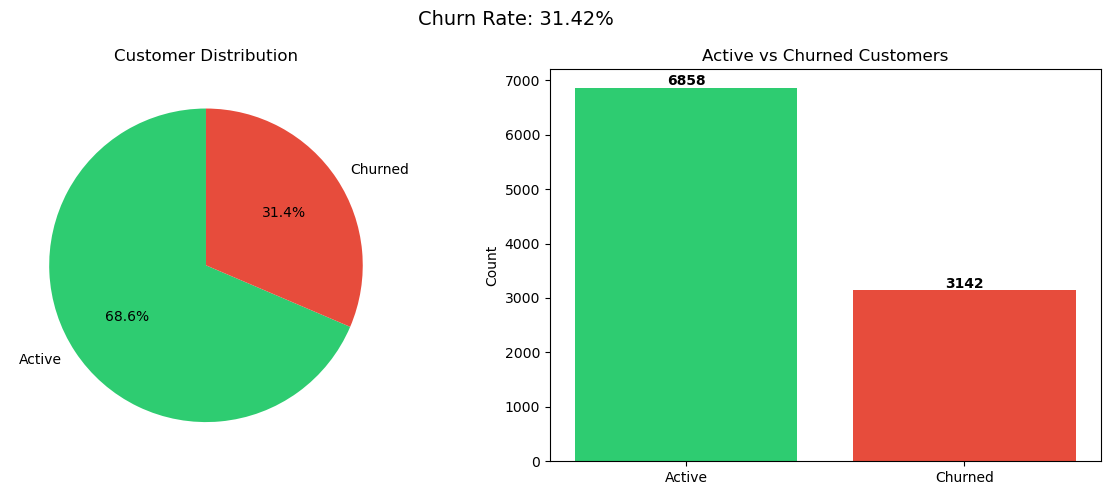

In [6]:
summary = get_churn_summary(df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
axes[0].pie(
    [summary['active_customers'], summary['churned_customers']],
    labels=['Active', 'Churned'],
    autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c'],
    startangle=90
)
axes[0].set_title('Customer Distribution')

# Bar chart
axes[1].bar(['Active', 'Churned'],
            [summary['active_customers'], summary['churned_customers']],
            color=['#2ecc71', '#e74c3c'])
axes[1].set_title('Active vs Churned Customers')
axes[1].set_ylabel('Count')
for i, v in enumerate([summary['active_customers'], summary['churned_customers']]):
    axes[1].text(i, v + 50, str(v), ha='center', fontweight='bold')

plt.suptitle(f"Churn Rate: {summary['churn_rate_pct']}%", fontsize=14)
plt.tight_layout()
plt.savefig('../outputs/churn_distribution.png', dpi=150)
plt.show()

## 1.5 Feature Identification

In [7]:
features = identify_features(df)
print('\nNumerical features :', features['numerical'])
print('Categorical features:', features['categorical'])
print('Excluded (leakage) :', features['excluded'])

Numerical  (10): ['Age', 'Monthly_Income', 'Monthly_Fee', 'Tenure_Months', 'Watch_Hours_Per_Month', 'Customer_Satisfaction', 'Support_Tickets', 'Buffering_Complaints', 'Concurrent_Screens', 'Recommendation_Clicks']
Categorical(8): ['Gender', 'State', 'City', 'Occupation', 'Subscription_Plan', 'Favorite_Genre', 'Device_Type', 'Payment_Method']

Numerical features : ['Age', 'Monthly_Income', 'Monthly_Fee', 'Tenure_Months', 'Watch_Hours_Per_Month', 'Customer_Satisfaction', 'Support_Tickets', 'Buffering_Complaints', 'Concurrent_Screens', 'Recommendation_Clicks']
Categorical features: ['Gender', 'State', 'City', 'Occupation', 'Subscription_Plan', 'Favorite_Genre', 'Device_Type', 'Payment_Method']
Excluded (leakage) : ['Customer_ID', 'Customer_Name', 'Churn_Type', 'Churn']


## 1.6 Churn Type Distribution

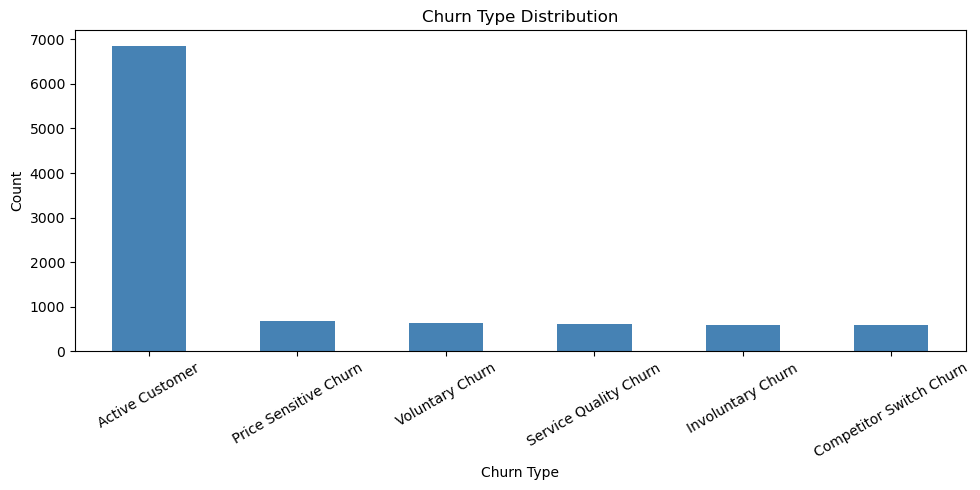

Churn_Type
Active Customer            6858
Price Sensitive Churn       687
Voluntary Churn             639
Service Quality Churn       615
Involuntary Churn           602
Competitor Switch Churn     599
Name: count, dtype: int64


In [8]:
if 'Churn_Type' in df.columns:
    ct = df['Churn_Type'].value_counts()
    fig, ax = plt.subplots(figsize=(10, 5))
    ct.plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title('Churn Type Distribution')
    ax.set_xlabel('Churn Type')
    ax.set_ylabel('Count')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig('../outputs/churn_type_distribution.png', dpi=150)
    plt.show()
    print(ct)

## Summary
- Dataset loaded and validated successfully.
- Churn target identified and distribution analyzed.
- Feature types (numerical / categorical) identified.
- Data leakage fields (Customer_ID, Customer_Name, Churn_Type) noted for exclusion.
- **Next step:** Notebook 02 — Data Preprocessing